<a href="https://colab.research.google.com/github/emanuelmejia/course_time_series_python/blob/main/L01-Intro_TS/notebooks/L01_IntroTS(B).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files
files.upload()

Saving pounds_nz.dat to pounds_nz.dat


{'pounds_nz.dat': b'xrate\n2.9243\n2.9422\n3.1719\n3.2542\n3.3479\n3.5066\n3.0027\n2.844\n2.8378\n2.7301\n2.7008\n2.6138\n2.5874\n2.5787\n2.547\n2.4701\n2.3895\n2.375\n2.3859\n2.2766\n2.2351\n2.245\n2.3208\n2.339\n2.3687\n2.512\n2.6917\n2.8435\n3.0922\n3.2528\n3.1852\n3.034\n2.9593\n3.0498\n3.1869\n3.2286\n3.1925\n3.3522\n3.531\n\n\n'}

In [3]:
df = pd.read_csv('/content/pounds_nz.dat')
df.head()

,xrate
0,2.9243
1,2.9422
2,3.1719
3,3.2542
4,3.3479


In [4]:
df['Fecha'] = pd.period_range(start='1991-01', periods=len(df), freq='Q')
df = df.set_index('Fecha')
df.head()

,xrate
Fecha,
1991Q1,2.9243
1991Q2,2.9422
1991Q3,3.1719
1991Q4,3.2542
1992Q1,3.3479


In [5]:
# Modificaciones a la tabla para los gráficos

# Calcular Promedio móvil para 12 periodos (datos mensuales)
df['promMovil'] = df['xrate'].rolling(window=4).mean()

# Extraer el mes del índice para el gráfico de cajas
df['Trimestre'] = df.index.quarter

df.tail()

,xrate,promMovil,Trimestre
Fecha,,,
1999Q3,3.1869,3.057500,3
1999Q4,3.2286,3.106150,4
2000Q1,3.1925,3.164450,1
2000Q2,3.3522,3.240050,2
2000Q3,3.5310,3.326075,3


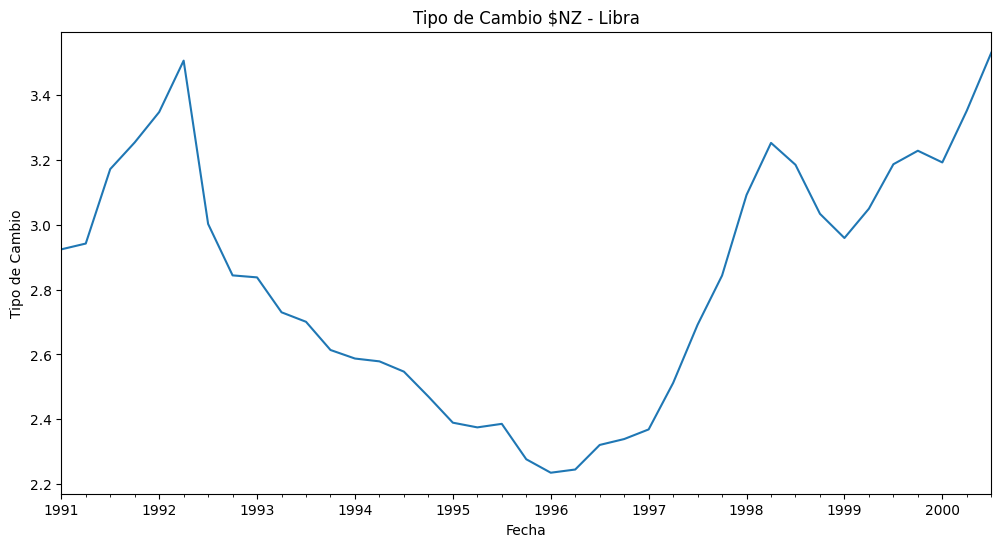

In [6]:
plt.figure(figsize=(12, 6))
df['xrate'].plot()
plt.title('Tipo de Cambio $NZ - Libra')
plt.xlabel('Fecha')
plt.ylabel('Tipo de Cambio')
plt.show()

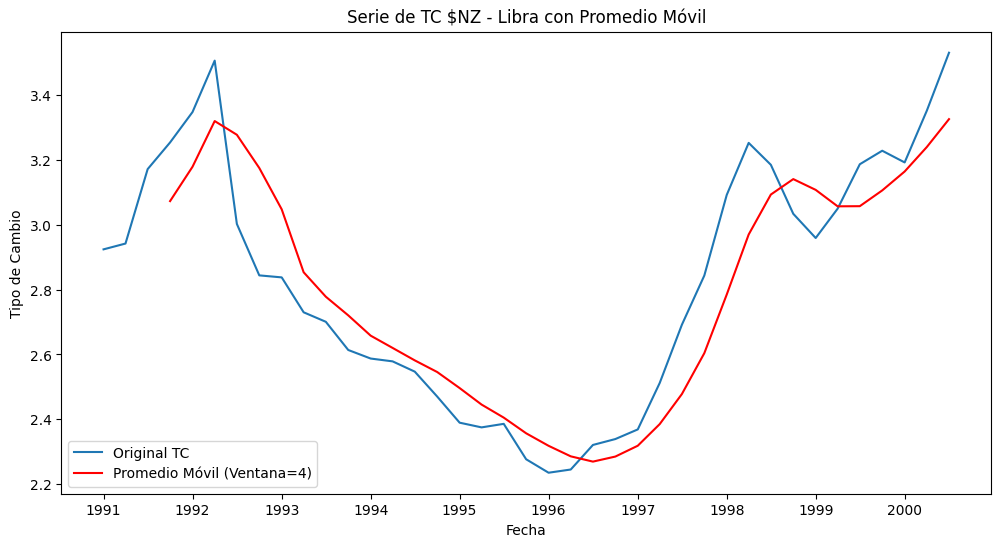

In [7]:
# Graficar serie original con promedio Móvil
plt.figure(figsize=(12, 6))
plt.plot(df['xrate'].index.to_timestamp(), df['xrate'], label='Original TC')
plt.plot(df['promMovil'].index.to_timestamp(), df['promMovil'], label='Promedio Móvil (Ventana=4)', color='red')
plt.title('Serie de TC $NZ - Libra con Promedio Móvil')
plt.xlabel('Fecha')
plt.ylabel('Tipo de Cambio')
plt.legend()

plt.show()

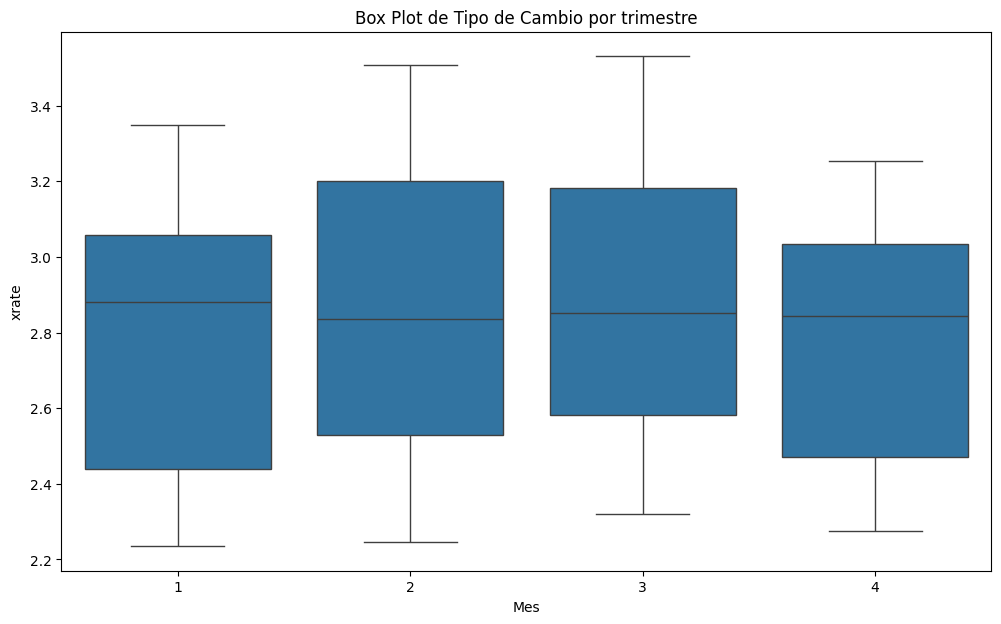

In [8]:
# Crear el gráfico de cajas
plt.figure(figsize=(12, 7))
sns.boxplot(x='Trimestre', y='xrate', data=df)
plt.title('Box Plot de Tipo de Cambio por trimestre')
plt.xlabel('Mes')
plt.ylabel('xrate')
plt.show()

In [9]:
df_1992_1995 = df.loc['1992':'1995']
df_1996_2000 = df.loc['1996':]

In [10]:
print("División de 1992 a 1995 (df_1992_1995):")
print(df_1992_1995)

División de 1992 a 1995 (df_1992_1995):
         xrate  promMovil  Trimestre
Fecha                               
1992Q1  3.3479   3.179050          1
1992Q2  3.5066   3.320150          2
1992Q3  3.0027   3.277850          3
1992Q4  2.8440   3.175300          4
1993Q1  2.8378   3.047775          1
1993Q2  2.7301   2.853650          2
1993Q3  2.7008   2.778175          3
1993Q4  2.6138   2.720625          4
1994Q1  2.5874   2.658025          1
1994Q2  2.5787   2.620175          2
1994Q3  2.5470   2.581725          3
1994Q4  2.4701   2.545800          4
1995Q1  2.3895   2.496325          1
1995Q2  2.3750   2.445400          2
1995Q3  2.3859   2.405125          3
1995Q4  2.2766   2.356750          4


In [11]:
print("División de 1996 a 2000")
print(df_1996_2000)

División de 1996 a 2000
         xrate  promMovil  Trimestre
Fecha                               
1996Q1  2.2351   2.318150          1
1996Q2  2.2450   2.285650          2
1996Q3  2.3208   2.269375          3
1996Q4  2.3390   2.284975          4
1997Q1  2.3687   2.318375          1
1997Q2  2.5120   2.385125          2
1997Q3  2.6917   2.477850          3
1997Q4  2.8435   2.603975          4
1998Q1  3.0922   2.784850          1
1998Q2  3.2528   2.970050          2
1998Q3  3.1852   3.093425          3
1998Q4  3.0340   3.141050          4
1999Q1  2.9593   3.107825          1
1999Q2  3.0498   3.057075          2
1999Q3  3.1869   3.057500          3
1999Q4  3.2286   3.106150          4
2000Q1  3.1925   3.164450          1
2000Q2  3.3522   3.240050          2
2000Q3  3.5310   3.326075          3


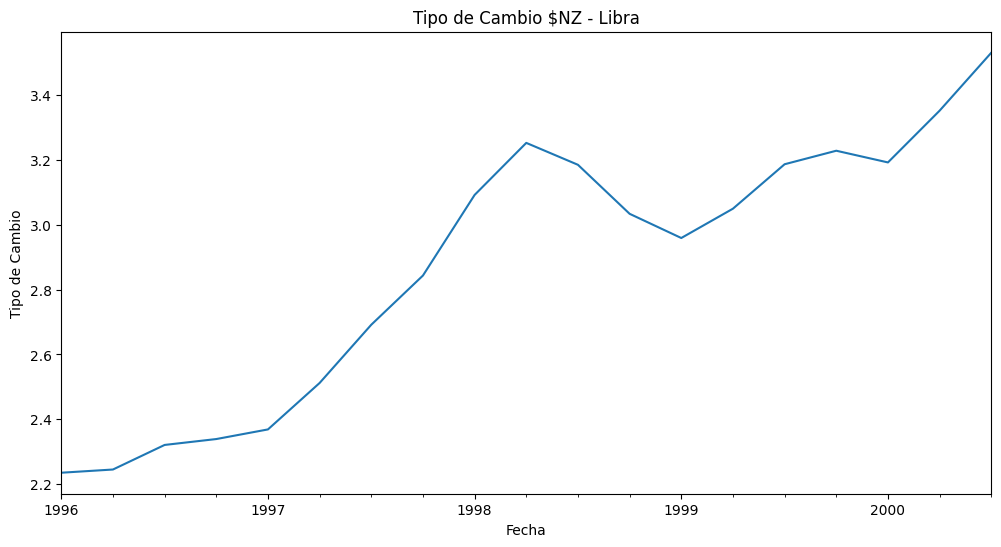

In [12]:
plt.figure(figsize=(12, 6))
df_1996_2000['xrate'].plot()
plt.title('Tipo de Cambio $NZ - Libra')
plt.xlabel('Fecha')
plt.ylabel('Tipo de Cambio')
plt.show()

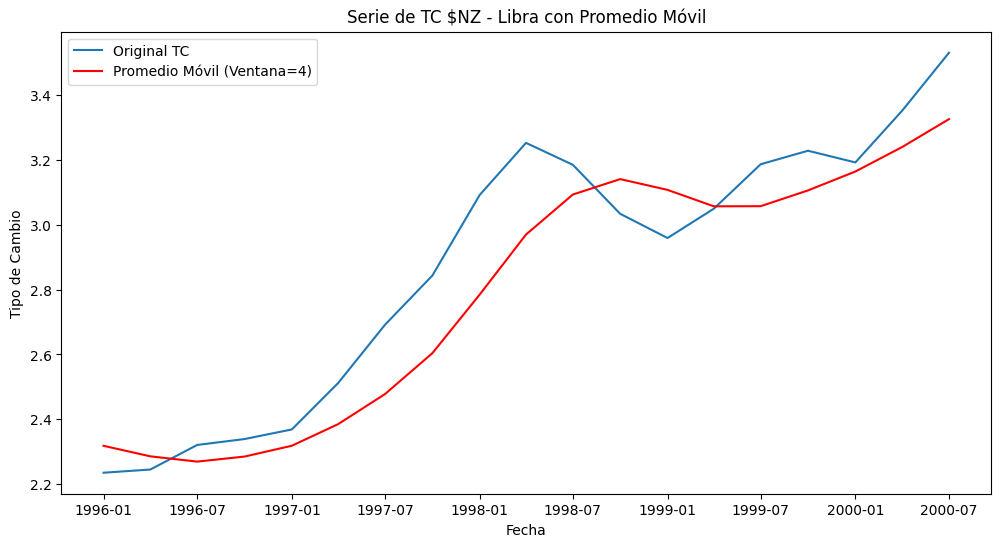

In [13]:
# Graficar serie original con promedio Móvil
plt.figure(figsize=(12, 6))
plt.plot(df_1996_2000['xrate'].index.to_timestamp(), df_1996_2000['xrate'], label='Original TC')
plt.plot(df_1996_2000['promMovil'].index.to_timestamp(), df_1996_2000['promMovil'], label='Promedio Móvil (Ventana=4)', color='red')
plt.title('Serie de TC $NZ - Libra con Promedio Móvil')
plt.xlabel('Fecha')
plt.ylabel('Tipo de Cambio')
plt.legend()

plt.show()

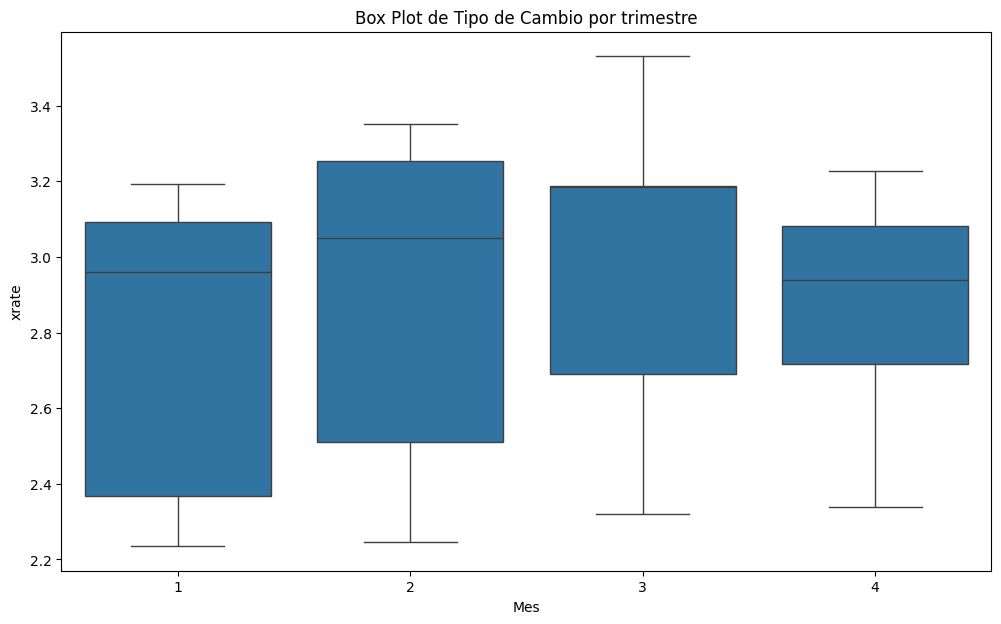

In [14]:
# Crear el gráfico de cajas
plt.figure(figsize=(12, 7))
sns.boxplot(x='Trimestre', y='xrate', data=df_1996_2000)
plt.title('Box Plot de Tipo de Cambio por trimestre')
plt.xlabel('Mes')
plt.ylabel('xrate')
plt.show()